In [1]:
import os 
print (os.listdir("/kaggle/input"))

['datasets']


In [2]:
import os
for root, dirs, files in os.walk("/kaggle/input/datasets"):
    print(root, "| qovluqlar:", dirs[:5], "| fayllar:", files[:3])
    if root.count("/") >= 6:
        break

/kaggle/input/datasets | qovluqlar: ['paramaggarwal'] | fayllar: []
/kaggle/input/datasets/paramaggarwal | qovluqlar: ['fashion-product-images-small'] | fayllar: []
/kaggle/input/datasets/paramaggarwal/fashion-product-images-small | qovluqlar: ['myntradataset', 'images'] | fayllar: ['styles.csv']
/kaggle/input/datasets/paramaggarwal/fashion-product-images-small/myntradataset | qovluqlar: ['images'] | fayllar: ['styles.csv']


In [3]:
import os
import pandas as pd

base = "/kaggle/input/datasets/paramaggarwal/fashion-product-images-small"
csv_path = os.path.join(base, "styles.csv")
img_dir  = os.path.join(base, "images")

print(os.path.exists(csv_path), os.path.exists(img_dir))
print(len(os.listdir(img_dir)))
print(os.listdir(img_dir)[:5])

True True
44441
['31973.jpg', '30778.jpg', '19812.jpg', '22735.jpg', '38246.jpg']


In [4]:
df = pd.read_csv(csv_path, on_bad_lines="skip")

I ran it on Kaggle rather than locally. In this environment, I load the 'styles.csv' file directly from the dataset's directory using its absolute path ('csv_path')."

Reading the file as df = pd.read_csv("styles.csv") will result in an error due to the "corrupted" lines inside. Therefore, we use on_bad_lines="skip" because it skips those lines and continues reading.

-------------------------------------------------------------------------------------------------------------------------------------
Lokalda yox Kaggledə yerinə yetirdim. Burada "styles.csv" faylını datasetin öz qovluğundan tam yolu ilə ("csv_path") oxuyuram.

Faylı "df = pd.read_csv("csv_path")" formasında oxutduqda içərisində olan"pozulmuş" sətirlər xətalı nəticə verəcək. Buna görə də, " on_bad_lines="skip" " istifadə edirik, çünki, həmin sətirləri atır və oxumağa davam edir. 

In [5]:
with open(csv_path, encoding="utf-8") as f:
    total_lines = sum(1 for _ in f) - 1

In [6]:
dropped = total_lines - len(df)

print("Line in file   :", total_lines)
print("Read line      :", len(df))
print("Thrown broken  :", dropped)

Line in file   : 44446
Read line      : 44424
Thrown broken  : 22


To determine the number of "skipped" lines, we first open the file as raw text and count the lines. Then, we calculate the difference.

-------------------------------------------------------------------------------------------------------------------------------------
"Atılan" sətirlərin sayını bilmək üçün ilk öncə, faylı xam mətn kimi açıb sətirləri sayırıq. Ardından fəqri hesablayırıq.

In [7]:
df.head()

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


In [8]:
df.shape

(44424, 10)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44424 entries, 0 to 44423
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  44424 non-null  int64  
 1   gender              44424 non-null  object 
 2   masterCategory      44424 non-null  object 
 3   subCategory         44424 non-null  object 
 4   articleType         44424 non-null  object 
 5   baseColour          44409 non-null  object 
 6   season              44403 non-null  object 
 7   year                44423 non-null  float64
 8   usage               44107 non-null  object 
 9   productDisplayName  44417 non-null  object 
dtypes: float64(1), int64(1), object(8)
memory usage: 3.4+ MB


In [10]:
df.isnull().sum()

id                      0
gender                  0
masterCategory          0
subCategory             0
articleType             0
baseColour             15
season                 21
year                    1
usage                 317
productDisplayName      7
dtype: int64

In [11]:
df.nunique()

id                    44424
gender                    5
masterCategory            7
subCategory              45
articleType             143
baseColour               46
season                    4
year                     13
usage                     8
productDisplayName    31121
dtype: int64

In [12]:
df["id"].is_unique

True

In [13]:
# 
before = len(df)
df = df.dropna(subset=["subCategory", "productDisplayName"]).reset_index(drop=True)
print("Dropped:", before - len(df))

Dropped: 7


In [14]:
df["usage"] = df["usage"].fillna("")
df["baseColour"] = df["baseColour"].fillna("")

In [15]:
df["text"] = (df["productDisplayName"] + " " + df["baseColour"] + " " + df["usage"]).str.strip()

The text input is constructed by combining the "productDisplayName", "baseColour", and "usage" columns. "productDisplayName" serves as the primary signal, since the product name typically directly identifies the product. "baseColour" and "usage" provide additional context as recommended in the task. "masterCategory" and "articleType" were intentionally excluded because they are too close to the target "subCategory", which would result in label leakage to the model. "gender", "season", and "year" were omitted as they carry little information about the category. Missing values in "baseColour" and "usage" were filled with empty strings to prevent row loss.

-------------------------------------------------------------------------------------------------------------------------------------
Mətn girişi "productDisplayName", "baseColour" və "usage" sütunlarının birləşdirilməsi ilə qurulub. "productDisplayName" əsas siqnaldır, çünki məhsul adı adətən məhsulu birbaşa bildirir. "baseColour" və "usage" tapşırıqda tövsiyə olunduğu kimi əlavə kontekst verir. "masterCategory" və "articleType" qəsdən daxil edilməyib, çünki hədəf olan "subCategory"-yə çox yaxındır və etiketi modelə açıq verərdi (label leakage). "gender", "season" və "year" kateqoriya haqqında az məlumat daşıdığı üçün çıxarılıb. Boş "baseColour" və "usage" dəyərləri boş sətirlə doldurulub ki, sətirlər itməsin.

In [16]:
df = df[["id", "subCategory", "text"]]

- Only the required features are kept: "id" (for image path), "subCategory" (label), and "text".
- "gender", "season", "year", "masterCategory", and "articleType" are discarded. "masterCategory" and "articleType" are highly correlated with the target label; including them would introduce data leakage to the model."

-------------------------------------------------------------------------------------------------------------------------------------
- Yalnız lazım olanlar qalır: "id" (şəkil yolu üçün), "subCategory" (etiket), "text" (mətn).
- "gender", "season", "year", "masterCategory", "articleType" atılır. "masterCategory" və "articleType" etiketə çox yaxındır, qalsa modelə “cavabı verməkdir.

In [17]:
df.shape

(44417, 3)

In [18]:
df.head()

,id,subCategory,text
0,15970,Topwear,Turtle Check Men Navy Blue Shirt Navy Blue Casual
1,39386,Bottomwear,Peter England Men Party Blue Jeans Blue Casual
2,59263,Watches,Titan Women Silver Watch Silver Casual
3,21379,Bottomwear,Manchester United Men Solid Black Track Pants ...
4,53759,Topwear,Puma Men Grey T-shirt Grey Casual


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44417 entries, 0 to 44416
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           44417 non-null  int64 
 1   subCategory  44417 non-null  object
 2   text         44417 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.0+ MB


In [20]:
df.isnull().sum()

id             0
subCategory    0
text           0
dtype: int64

In [21]:
# We delete rows that are not images.

df["img_path"] = df["id"].astype(str).apply(lambda i: os.path.join(img_dir, i + ".jpg"))
exists = df["img_path"].apply(os.path.exists)
print("Missing image:", (~exists).sum())
df = df[exists].reset_index(drop=True)
print("Rows left:", len(df))

Missing image: 5
Rows left: 44412


subCategory
Topwear                     15398
Shoes                        7343
Bags                         3053
Bottomwear                   2693
Watches                      2542
Innerwear                    1808
Jewellery                    1079
Eyewear                      1073
Fragrance                    1006
Sandal                        963
Wallets                       933
Flip Flops                    913
Belts                         811
Socks                         698
Lips                          527
Dress                         478
Loungewear and Nightwear      470
Saree                         427
Nails                         329
Makeup                        307
Headwear                      293
Ties                          258
Accessories                   129
Scarves                       118
Cufflinks                     108
Apparel Set                   106
Free Gifts                    104
Stoles                         90
Skin Care                      77
Sk

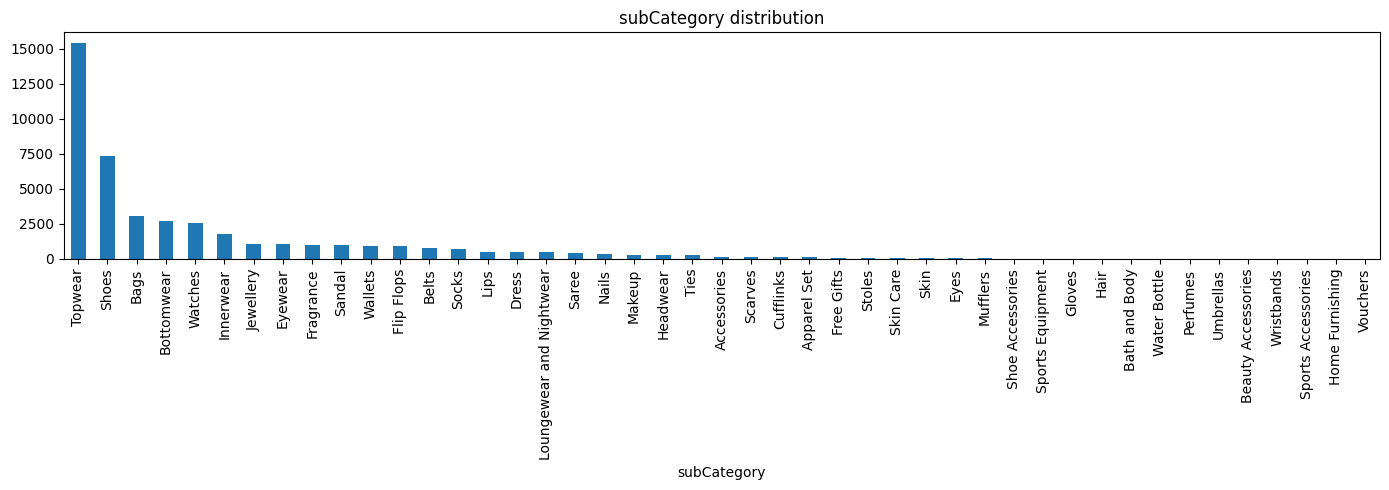

In [22]:
# Class distribution.

import matplotlib.pyplot as plt
counts = df["subCategory"].value_counts()
print(counts)
print("Top class share: %.1f%%" % (counts.iloc[0] / len(df) * 100))
counts.plot(kind="bar", figsize=(14, 5), title="subCategory distribution")
plt.tight_layout()
plt.show()

The target "subCategory" has 45 classes and is strongly imbalanced. The largest class (Topwear) makes up about x% of the data, while the smallest classes have only a handful of samples. Because of this, plain accuracy would be misleading (a model predicting “Topwear” for everything would already score ~x%), so macro F1 is used as the main metric. In the next step, classes with fewer than 10 instances will be deleted.

----------------------------------------------------------------------------------------------------------
Hədəf "subCategory" 45 sinifdən ibarətdir və ciddi balanssızdır. Ən böyük sinif (Topwear) datanın təxminən x%-ni təşkil edir, ən kiçik siniflərdə isə cəmi bir neçə nümunə var. Buna görə accuracy aldadıcı olardı (model hər şeyə “Topwear” desə belə ~x% düz çıxar), ona görə əsas metrik kimi macro F1 seçilib. Növbəti addımda 10-dan az nümunəsi olan siniflər silinəcək.

In [23]:
print(counts[counts < 10])
valid = counts[counts >= 10].index
df = df[df["subCategory"].isin(valid)].reset_index(drop=True)
print("Classes left:", df["subCategory"].nunique(), "| Rows:", len(df))

subCategory
Water Bottle          7
Perfumes              6
Umbrellas             6
Beauty Accessories    4
Wristbands            4
Sports Accessories    3
Home Furnishing       1
Vouchers              1
Name: count, dtype: int64
Classes left: 37 | Rows: 44380


Classes with fewer than 10 samples were dropped: 8 classes, 32 rows (~0.07% of the data), leaving 37 classes and 44,380 rows. With a stratified 70/15/15 split such classes would have 0–1 samples in validation/test, making stratify fail (classes with 1 sample) and per-class F1 random, which would make macro F1 unreliable for comparing models. Merging them into “Other” was rejected because it would mix unrelated products into a meaningless class.

----------------------------------------------------------------------------------------------------------
10-dan az nümunəsi olan 8 sinif silindi (32 sətir, datanın ~0.07%-i), 37 sinif və 44,380 sətir qaldı. Belə siniflər stratified split-də val/test-də 0-1 nümunə ilə qalır (1 nümunəli sinifdə stratify xəta verir), F1 təsadüfi olur və macro F1 modelləri müqayisə üçün etibarsızlaşır. “Other”-ə birləşdirmə əlaqəsiz məhsulları qarışdıracağı üçün seçilmədi.

In [24]:
df.shape

(44380, 4)

In [25]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df["label"] = le.fit_transform(df["subCategory"])

num_classes = len(le.classes_)
print("Classes:", num_classes)
print(dict(zip(le.classes_[:5], range(5))))

Classes: 37
{'Accessories': 0, 'Apparel Set': 1, 'Bags': 2, 'Bath and Body': 3, 'Belts': 4}


In [26]:
df.shape

(44380, 5)

In [27]:
df.head()

,id,subCategory,text,img_path,label
0,15970,Topwear,Turtle Check Men Navy Blue Shirt Navy Blue Casual,/kaggle/input/datasets/paramaggarwal/fashion-p...,34
1,39386,Bottomwear,Peter England Men Party Blue Jeans Blue Casual,/kaggle/input/datasets/paramaggarwal/fashion-p...,5
2,59263,Watches,Titan Women Silver Watch Silver Casual,/kaggle/input/datasets/paramaggarwal/fashion-p...,36
3,21379,Bottomwear,Manchester United Men Solid Black Track Pants ...,/kaggle/input/datasets/paramaggarwal/fashion-p...,5
4,53759,Topwear,Puma Men Grey T-shirt Grey Casual,/kaggle/input/datasets/paramaggarwal/fashion-p...,34


In [28]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=42
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=42
)

print("Train:", len(train_df), "| Val:", len(val_df), "| Test:", len(test_df))

Train: 31066 | Val: 6657 | Test: 6657


In [29]:
for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    top = part["subCategory"].value_counts(normalize=True).iloc[0] * 100
    print(f"{name}: {len(part)} rows | top class share: {top:.1f}%")

print("Min samples per class in test:", test_df["label"].value_counts().min())

train: 31066 rows | top class share: 34.7%
val: 6657 rows | top class share: 34.7%
test: 6657 rows | top class share: 34.7%
Min samples per class in test: 2


**Label encoding.** The target "subCategory" (37 classes after removing rare ones) was converted to integer labels (0–36) with "LabelEncoder", because PyTorch's "CrossEntropyLoss" expects numeric class indices. The encoder is kept to map predictions back to class names in the confusion matrix and error analysis.

**Stratified split.** The data was split once into train / validation / test = 70% / 15% / 15% (31,066 / 6,657 / 6,657 rows) with "stratify=label" and "random_state=42". Stratification keeps class proportions identical in all three parts (the largest class, Topwear, is 34.7% in each), and the smallest class still has 2 samples in the test set. This single split is reused by all three models (image-only, text-only, fused), which is what makes the comparison fair. The test set is used only for the final evaluation.

---

**Etiketlərin kodlaşdırılması.** Hədəf "subCategory" (nadir siniflər silindikdən sonra 37 sinif) "LabelEncoder" ilə 0–36 rəqəmlərinə çevrildi, çünki PyTorch-un "CrossEntropyLoss" funksiyası rəqəmli sinif indeksi tələb edir. Encoder saxlanılır ki, confusion matrix və error analysis-də proqnozları sinif adlarına qaytaraq.

**Stratified split.** Data bir dəfə train / validation / test = 70% / 15% / 15% (31,066 / 6,657 / 6,657 sətir) nisbətində, "stratify=label" və "random_state=42" ilə bölündü. Stratifikasiya sinif nisbətlərini üç hissədə eyni saxlayır (ən böyük sinif Topwear hər birində 34.7%-dir), ən kiçik sinifdə isə test-də hələ də 2 nümunə var. Bu vahid split üç modelin hamısı (yalnız şəkil, yalnız mətn, fusion) tərəfindən istifadə olunur, müqayisəni ədalətli edən də budur. Test seti yalnız yekun qiymətləndirmə üçün istifadə olunur.

In [30]:
train_df.to_csv("/kaggle/working/train.csv", index=False)
val_df.to_csv("/kaggle/working/val.csv", index=False)
test_df.to_csv("/kaggle/working/test.csv", index=False)

The three splits are saved to CSV files so that all three models load exactly the same train/validation/test data, even if the session restarts.

---
Üç split CSV fayllarına saxlanılır ki, sessiya yenidən başlasa belə, üç modelin hamısı eyni train/validation/test datasını yükləsin.

## Data Pipeline: Image Transforms, Tokenizer and Shared Dataset

In [31]:
from torchvision import transforms

IMG_SIZE = 224
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),])

eval_tf = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),])

Since the dataset images are 60×80 and ResNet was trained on 224×224 ImageNet data, using different dimensions and normalization will degrade the performance of pretrained weights. To prevent this, we resize each image to 224×224, convert it to a tensor, and apply ImageNet's mean/std normalization. For the training set, we also incorporate data augmentation - like random flips, minor rotations, and color adjustments - to mitigate overfitting.

------
Dataset şəkilləri 60×80-dir, ResNet isə ImageNet-də 224×224 ilə öyrənib. Eyni ölçü və eyni normallaşdırma verməsək, pretrained çəkilər pis işləyir. 
Buna görə də hər şəkli 224×224-ə gətirir, tensora çevirir və ImageNet mean/std ilə normallaşdırırıq. Train üçün əlavə olaraq təsadüfi flip, kiçik fırlatma və rəng dəyişikliyi (augmentasiya) tətbiq olunur.
Augmentasiya modelin əzbərləməsini (overfitting) azaldır. 

In [32]:
from transformers import AutoTokenizer

MAX_LEN = 32
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

sample = tokenizer(df["text"].iloc[0], padding="max_length",
                   truncation=True, max_length=MAX_LEN)
print(sample["input_ids"][:10])

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[101, 13170, 4638, 2273, 3212, 2630, 3797, 3212, 2630, 10017]


The tokenizer converts the text into tokens using DistilBERT's vocabulary and pads short sequences with zeros up to a length of 32, while the attention mask indicates to the model which tokens are actual text and which are padding.

------
Tokenizer mətni DistilBERT-in lüğəti ilə rəqəmlərə çevirir, qısa mətnləri 32-yə qədər 0-la doldurur, attention mask isə modelə deyir ki, hansı rəqəmlər real, hansılar boşdur.

In [33]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class ProductDataset(Dataset):
    def __init__(self, df, tokenizer, img_tf, max_len=32):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.img_tf = img_tf
        self.max_len = max_len

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        image = Image.open(row["img_path"]).convert("RGB")
        image = self.img_tf(image)
        enc = self.tokenizer(row["text"], padding="max_length",truncation=True, max_length=self.max_len,
                             return_tensors="pt")
        return {"image": image, "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "label": torch.tensor(row["label"], dtype=torch.long),}

In [34]:
BATCH = 64

train_ds = ProductDataset(train_df, tokenizer, train_tf, MAX_LEN)
val_ds   = ProductDataset(val_df,   tokenizer, eval_tf,  MAX_LEN)
test_ds  = ProductDataset(test_df,  tokenizer, eval_tf,  MAX_LEN)

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=2)

batch = next(iter(train_loader))
print(batch["image"].shape, batch["input_ids"].shape, batch["label"].shape)

torch.Size([64, 3, 224, 224]) torch.Size([64, 32]) torch.Size([64])


Our initial file was a dataframe containing image paths, text, and labels, but the model expects tensors rather than tabular data. The Dataset class transforms each row into a model-readable format, and the DataLoader batches these samples to feed them into the model.

------
Əlimizdə olan faylda cədvəl var idi (şəkil yolu, mətn, etiket). Model isə cədvəl yox, tensor istəyir. Dataset cədvəlin hər sətrini modelin oxuya biləcəyi formaya çevirir, DataLoader isə bunları qruplara (batch) yığıb modelə verir.

## Shared Training and Evaluation Setup

In [35]:
import torch, torch.nn as nn, numpy as np, json, time
from sklearn.metrics import accuracy_score, f1_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

EPOCHS = 3
results, histories, predictions = {}, {}, {}

def run_epoch(model, loader, forward_fn, criterion, optimizer=None):
    train = optimizer is not None
    model.train() if train else model.eval()
    total_loss, y_true, y_pred = 0.0, [], []
    with torch.set_grad_enabled(train):
        for batch in loader:
            labels = batch["label"].to(device)
            logits = forward_fn(model, batch)
            loss = criterion(logits, labels)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            y_true += labels.cpu().tolist()
            y_pred += logits.argmax(1).cpu().tolist()
    n = len(y_true)
    return total_loss / n, f1_score(y_true, y_pred, average="macro"), y_true, y_pred

def fit(name, model, forward_fn, optimizer):
    criterion = nn.CrossEntropyLoss()
    hist = {"train_loss": [], "val_loss": [], "val_f1": []}
    best_f1, best_state = -1, None
    for ep in range(EPOCHS):
        t0 = time.time()
        tr_loss, _, _, _ = run_epoch(model, train_loader, forward_fn, criterion, optimizer)
        va_loss, va_f1, _, _ = run_epoch(model, val_loader, forward_fn, criterion)
        hist["train_loss"].append(tr_loss); hist["val_loss"].append(va_loss); hist["val_f1"].append(va_f1)
        if va_f1 > best_f1:
            best_f1 = va_f1
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(f"[{name}] epoch {ep+1}/{EPOCHS} | train {tr_loss:.3f} | val {va_loss:.3f} | val macroF1 {va_f1:.3f} | {time.time()-t0:.0f}s")
    model.load_state_dict(best_state)
    _, _, y_true, y_pred = run_epoch(model, test_loader, forward_fn, criterion)
    histories[name] = hist
    predictions[name] = {"y_true": y_true, "y_pred": y_pred}
    results[name] = {"accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted"),}
    json.dump(results, open("/kaggle/working/results.json", "w"), indent=2)
    print(name, results[name])

Device: cuda


All three models are trained and evaluated with the same "fit()" function: same split, same number of epochs (3), same optimiser family (AdamW), same loss (CrossEntropy) and the same metric (macro F1). After each epoch the validation macro F1 is computed and the best epoch's weights are kept. The test set is used only once at the end. Training curves, test predictions and metrics are stored for every model.

---

Üç model eyni "fit()" funksiyası ilə öyrədilir və qiymətləndirilir: eyni split, eyni epoch sayı (3), eyni optimizer ailəsi (AdamW), eyni loss (CrossEntropy) və eyni metrika (macro F1). Hər epoch-dan sonra validation macro F1 hesablanır və ən yaxşı epoch-un çəkiləri saxlanılır. Test seti yalnız sonda, bir dəfə istifadə olunur. Hər model üçün təlim əyriləri, test proqnozları və metrikalar saxlanılır.

## Model A: Image-only (ResNet18)

In [36]:
from torchvision import models

num_classes = df["label"].nunique()

model_A = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model_A.fc = nn.Linear(512, num_classes)
model_A = model_A.to(device)

fwd_A = lambda m, b: m(b["image"].to(device))
opt_A = torch.optim.AdamW(model_A.parameters(), lr=1e-4)

fit("A_image", model_A, fwd_A, opt_A)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 217MB/s]


[A_image] epoch 1/3 | train 0.399 | val 0.177 | val macroF1 0.645 | 242s
[A_image] epoch 2/3 | train 0.160 | val 0.142 | val macroF1 0.772 | 116s
[A_image] epoch 3/3 | train 0.115 | val 0.136 | val macroF1 0.786 | 115s
A_image {'accuracy': 0.9618446747784287, 'macro_f1': 0.7670292961704657, 'weighted_f1': 0.959678758649323}


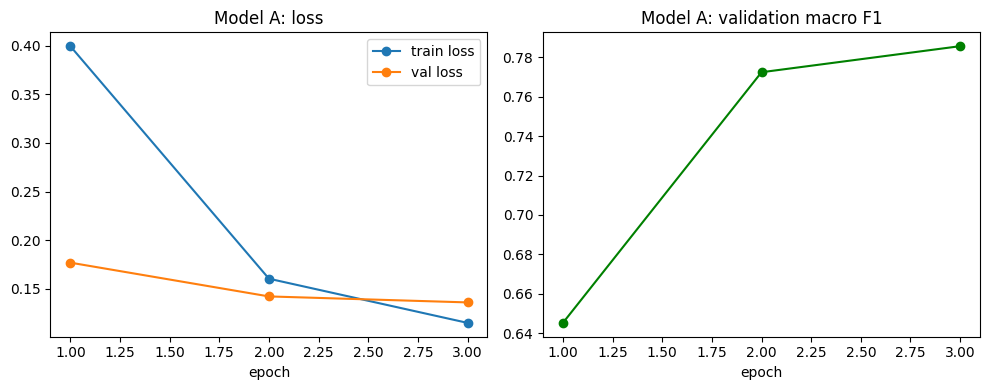

In [37]:
import matplotlib.pyplot as plt

h = histories["A_image"]
epochs = range(1, len(h["train_loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(epochs, h["train_loss"], marker="o", label="train loss")
ax[0].plot(epochs, h["val_loss"], marker="o", label="val loss")
ax[0].set_title("Model A: loss"); ax[0].set_xlabel("epoch"); ax[0].legend()

ax[1].plot(epochs, h["val_f1"], marker="o", color="green")
ax[1].set_title("Model A: validation macro F1"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

To perform prediction on an image, we establish an image baseline.

A pretrained ResNet18 (ImageNet) turns each image into a 512-number feature vector. Its original 1000-class output layer is replaced by a new "Linear(512, 37)" layer that maps these features to scores for our 37 classes. The whole network is fine-tuned (no frozen layers) with AdamW (lr 1e-4), 3 epochs, same split and loss as the other models. The best epoch is chosen by validation macro F1; the test set is used once at the end.

Accuracy (0.96) is much higher than macro F1 (0.77). The large classes (e.g. Topwear, Shoes) are predicted well, while rare classes are weaker, so accuracy flatters the model. This confirms that macro F1 is the honest metric here. Images are only 60×80 pixels (upsampled to 224), yet the image baseline is already fairly strong.

---
Şəkil üzərindən proqnozlaşdırma aparmaq üçün, şəkil baseline qururuq.

Pretrained ResNet18 hər şəkli 512 rəqəmlik xüsusiyyət vektoruna çevirir. Orijinal 1000 sinifli çıxış qatı yeni "Linear(512, 37)" qatı ilə əvəz olunub. Bütün şəbəkə fine-tune olunur (dondurulmuş qat yoxdur), AdamW (lr 1e-4), 3 epoch, digər modellərlə eyni split və loss. Ən yaxşı epoch validation macro F1 ilə seçilir, test seti yalnız sonda bir dəfə istifadə olunur.

Accuracy (0.96) macro F1-dən (0.77) xeyli yüksəkdir. Böyük siniflər (Topwear, Shoes) yaxşı tapılır, nadir siniflər zəifdir, ona görə accuracy modeli olduğundan yaxşı göstərir. Bu, macro F1-in dürüst metrika olduğunu təsdiqləyir. Şəkillər cəmi 60×80-dir (224-ə böyüdülür), buna baxmayaraq şəkil baseline-ı kifayət qədər güclüdür.

## Model B: Text-only (DistilBERT)

In [38]:
from transformers import AutoModel

class TextModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.bert = AutoModel.from_pretrained("distilbert-base-uncased")
        self.head = nn.Linear(768, num_classes)

    def forward(self, input_ids, attention_mask):
        out = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls = out.last_hidden_state[:, 0]
        return self.head(cls)

model_B = TextModel(num_classes).to(device)
fwd_B = lambda m, b: m(b["input_ids"].to(device), b["attention_mask"].to(device))
opt_B = torch.optim.AdamW(model_B.parameters(), lr=2e-5)

fit("B_text", model_B, fwd_B, opt_B)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[B_text] epoch 1/3 | train 0.408 | val 0.073 | val macroF1 0.851 | 120s
[B_text] epoch 2/3 | train 0.060 | val 0.053 | val macroF1 0.913 | 102s
[B_text] epoch 3/3 | train 0.041 | val 0.046 | val macroF1 0.927 | 103s
B_text {'accuracy': 0.9890340994441941, 'macro_f1': 0.9141527834829198, 'weighted_f1': 0.98820514853833}


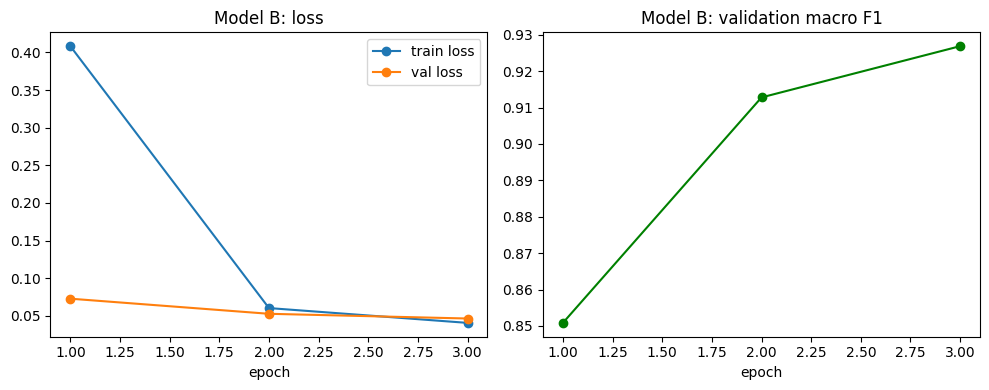

In [41]:
h_b = histories["B_text"]
epochs_b = range(1, len(h_b["train_loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot(epochs_b, h_b["train_loss"], marker="o", label="train loss")
ax[0].plot(epochs_b, h_b["val_loss"], marker="o", label="val loss")
ax[0].set_title("Model B: loss")
ax[0].set_xlabel("epoch")
ax[0].legend()

ax[1].plot(epochs_b, h_b["val_f1"], marker="o", color="green")
ax[1].set_title("Model B: validation macro F1")
ax[1].set_xlabel("epoch")

plt.tight_layout()
plt.show()

A Text baseline is set up to know how well it can predict a category based on the product name (with color and usage) alone.

A pretrained DistilBERT encoder; the `[CLS]` vector (768-d) of the tokenised text goes through a new `Linear(768, 37)` head. The whole encoder is fine-tuned with a small learning rate (2e-5) so the pretrained weights are not destroyed. AdamW, 3 epochs, same split, loss and best-epoch selection (validation macro F1) as the other models.

Text is a very strong signal: product titles usually name the item directly (e.g. "Puma Men Grey T-shirt"), so the text baseline is clearly stronger than the image baseline (macro F1 0.914 vs 0.767).

---
Yalnız məhsul adı (rəng və usage ilə) əsasında kateqoriyanı nə qədər proqnozlaşdıracağını bilmək üçün Mətn baseline-ı qurulur.

Pretrained DistilBERT - tokenləşdirilmiş mətnin `[CLS]` vektoru (768) yeni `Linear(768, 37)` başlığından keçir. Encoder kiçik LR (2e-5) ilə tam fine-tune olunur. AdamW, 3 epoch, digər modellərlə eyni split, loss və ən yaxşı epoch seçimi.

Mətn çox güclü siqnaldır, məhsul adı adətən məhsulu birbaşa bildirir, ona görə mətn baseline-ı şəkildən xeyli güclüdür (0.914 vs 0.767).

## Model C: Fused (ResNet18 + DistilBERT).

In [39]:
class FusionModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        cnn = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        cnn.fc = nn.Identity()
        self.cnn = cnn
        self.bert = AutoModel.from_pretrained("distilbert-base-uncased")
        self.mlp = nn.Sequential(nn.Linear(512 + 768, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),)

    def forward(self, image, input_ids, attention_mask):
        img_feat = self.cnn(image)
        txt_feat = self.bert(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0]
        return self.mlp(torch.cat([img_feat, txt_feat], dim=1))

model_C = FusionModel(num_classes).to(device)
fwd_C = lambda m, b: m(b["image"].to(device), b["input_ids"].to(device), b["attention_mask"].to(device))

opt_C = torch.optim.AdamW([{"params": model_C.cnn.parameters(),  "lr": 1e-4},
    {"params": model_C.bert.parameters(), "lr": 2e-5},
    {"params": model_C.mlp.parameters(),  "lr": 1e-3},])

fit("C_fusion", model_C, fwd_C, opt_C)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[C_fusion] epoch 1/3 | train 0.232 | val 0.063 | val macroF1 0.924 | 205s
[C_fusion] epoch 2/3 | train 0.048 | val 0.058 | val macroF1 0.887 | 205s
[C_fusion] epoch 3/3 | train 0.034 | val 0.050 | val macroF1 0.919 | 204s
C_fusion {'accuracy': 0.9878323569175305, 'macro_f1': 0.8998388517201665, 'weighted_f1': 0.9869603067076773}


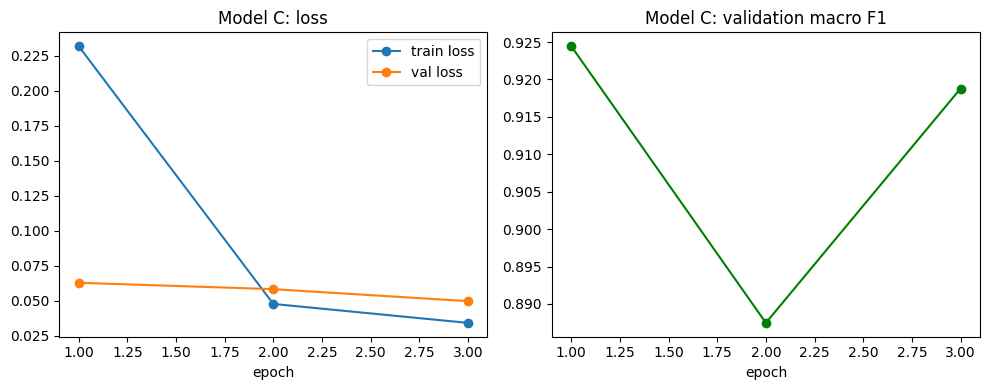

In [42]:
h_c = histories["C_fusion"]
epochs_c = range(1, len(h_c["train_loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot(epochs_c, h_c["train_loss"], marker="o", label="train loss")
ax[0].plot(epochs_c, h_c["val_loss"], marker="o", label="val loss")
ax[0].set_title("Model C: loss")
ax[0].set_xlabel("epoch")
ax[0].legend()

ax[1].plot(epochs_c, h_c["val_f1"], marker="o", color="green")
ax[1].set_title("Model C: validation macro F1")
ax[1].set_xlabel("epoch")

plt.tight_layout()
plt.show()

We test whether combining images and text is better than either modality alone.

Two pretrained encoders run in parallel: ResNet18 (512-d image vector, classification layer removed) and DistilBERT (768-d `[CLS]` text vector). The vectors are concatenated (1280-d) and passed through an MLP (1280→256→37, ReLU, dropout 0.3). Both encoders are fine-tuned (no freezing) with separate learning rates: ResNet 1e-4, DistilBERT 2e-5, new MLP 1e-3. AdamW, 3 epochs, same split and loss. This is late fusion: modalities are encoded separately and combined at the feature level.

Fusion did not beat the text-only model (0.900 vs 0.914), though it is far above the image-only model (0.767). Because the text already names the product category, the image adds little new information. The difference to text-only is small and, with one training run, may be within noise.

---
Şəkil və mətnin birləşdirilməsinin tək-tək modallıqlardan yaxşı olub-olmadığını yoxlayırıq.

İki pretrained encoder paralel işləyir - ResNet18 (512 şəkil vektoru) və DistilBERT (768 mətn vektoru). Vektorlar birləşdirilir (1280) və MLP-dən (1280→256→37) keçir. Hər iki encoder fine-tune olunur, fərqli LR-lərlə (1e-4, 2e-5, 1e-3). AdamW, 3 epoch. Bu late fusion-dur.

Fusion mətn modelini üstələmədi (0.900 vs 0.914), amma şəkil modelindən çox yüksəkdir (0.767). Mətn kateqoriyanı artıq bildirdiyi üçün şəkil az yeni məlumat əlavə edir. Fərq kiçikdir və bir təlim run-ı ilə təsadüf daxilində ola bilər.

# Evaluation

## Three-Way Model Comparison

In [44]:
names = {"A_image": "A: Image-only (ResNet18)",
         "B_text":  "B: Text-only (DistilBERT)",
         "C_fusion":"C: Fused (late fusion)"}

comp = pd.DataFrame(results).T.rename(index=names)
comp = comp[["accuracy", "macro_f1", "weighted_f1"]].round(4)
comp["macro_f1_vs_text"] = (comp["macro_f1"] - comp.loc[names["B_text"], "macro_f1"]).round(4)
display(comp)

comp.to_csv("/kaggle/working/comparison_table.csv")

,accuracy,macro_f1,weighted_f1,macro_f1_vs_text
A: Image-only (ResNet18),0.9618,0.7670,0.9597,-0.1472
B: Text-only (DistilBERT),0.9890,0.9142,0.9882,0.0000
C: Fused (late fusion),0.9878,0.8998,0.9870,-0.0144


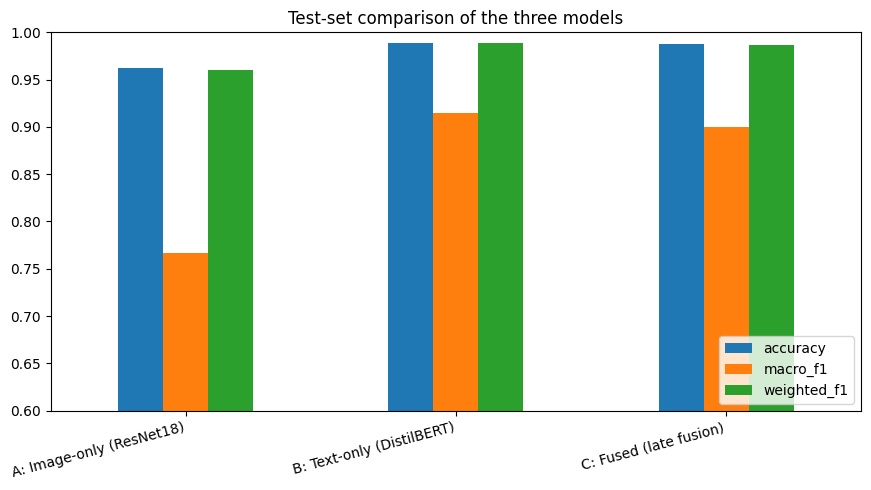

In [45]:
ax = comp[["accuracy", "macro_f1", "weighted_f1"]].plot(kind="bar", figsize=(9, 5))
ax.set_title("Test-set comparison of the three models")
ax.set_ylim(0.6, 1.0)
ax.set_xticklabels(comp.index, rotation=15, ha="right")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

All three models were trained with the same stratified split, the same number of epochs (3), the same optimiser family (AdamW), the same loss and the same selection rule (best validation macro F1) and evaluated once on the same test set (6,657 rows, 37 classes).

The data is imbalanced (the largest class, Topwear, is 34.7% of rows). Accuracy is dominated by large classes, the image model loses only 2.7 points of accuracy against the text model but 14.7 points of macro F1. Macro F1 averages the per-class F1 with equal weight, so rare classes count as much as frequent ones and the metric reflects real performance across all 37 classes.

- Text-only is the strongest model (macro F1 0.914): product titles usually name the item directly.
- Image-only is the weakest (0.767), partly because the source images are only 60×80 pixels.
- The fused model (0.900) is far better than image-only but slightly below text-only (−0.014). Since the text already names the category, the image adds little new information.
- Each model was trained once, so a difference of 0.014 may be within run-to-run noise. We therefore say fusion "did not help" rather than "hurt".

---
Üç model eyni stratified split, eyni epoch sayı (3), eyni optimizer ailəsi (AdamW), eyni loss və eyni seçim qaydası (ən yaxşı validation macro F1) ilə öyrədilib və eyni test setində (6,657 sətir, 37 sinif) bir dəfə qiymətləndirilib.

Data balanssızdır (ən böyük sinif Topwear sətirlərin 34.7%-dir). Accuracy böyük siniflərin təsiri altındadır. Şəkil modeli mətn modelindən accuracy-də cəmi 2.7 bənd, macro F1-də isə 14.7 bənd geridədir. Macro F1 hər sinfin F1-ini bərabər çəki ilə ortalayır, ona görə nadir siniflər də böyük siniflər qədər sayılır və 37 sinifin hamısında real performansı göstərir.

- Mətn modeli ən güclüdür (macro F1 0.914): məhsul adı adətən məhsulu birbaşa bildirir.
- Şəkil modeli ən zəifdir (0.767), qismən ona görə ki, orijinal şəkillər cəmi 60×80 pikseldir.
- Fusion modeli (0.900) şəkildən çox yüksəkdir, amma mətndən bir qədər aşağıdır (−0.014). Mətn kateqoriyanı artıq bildirdiyi üçün şəkil az yeni məlumat əlavə edir.
- Hər model bir dəfə öyrədilib, ona görə 0.014 fərq təsadüf daxilində ola bilər. Buna görə "fusion zərər verdi" yox, "kömək etmədi" deyirik.

## Confusion Matrix and Per-Class F1

In [46]:
from sklearn.metrics import confusion_matrix, classification_report, f1_score

class_names = list(le.classes_)
labels_all = list(range(len(class_names)))

yt = np.array(predictions["C_fusion"]["y_true"])
yp = np.array(predictions["C_fusion"]["y_pred"])

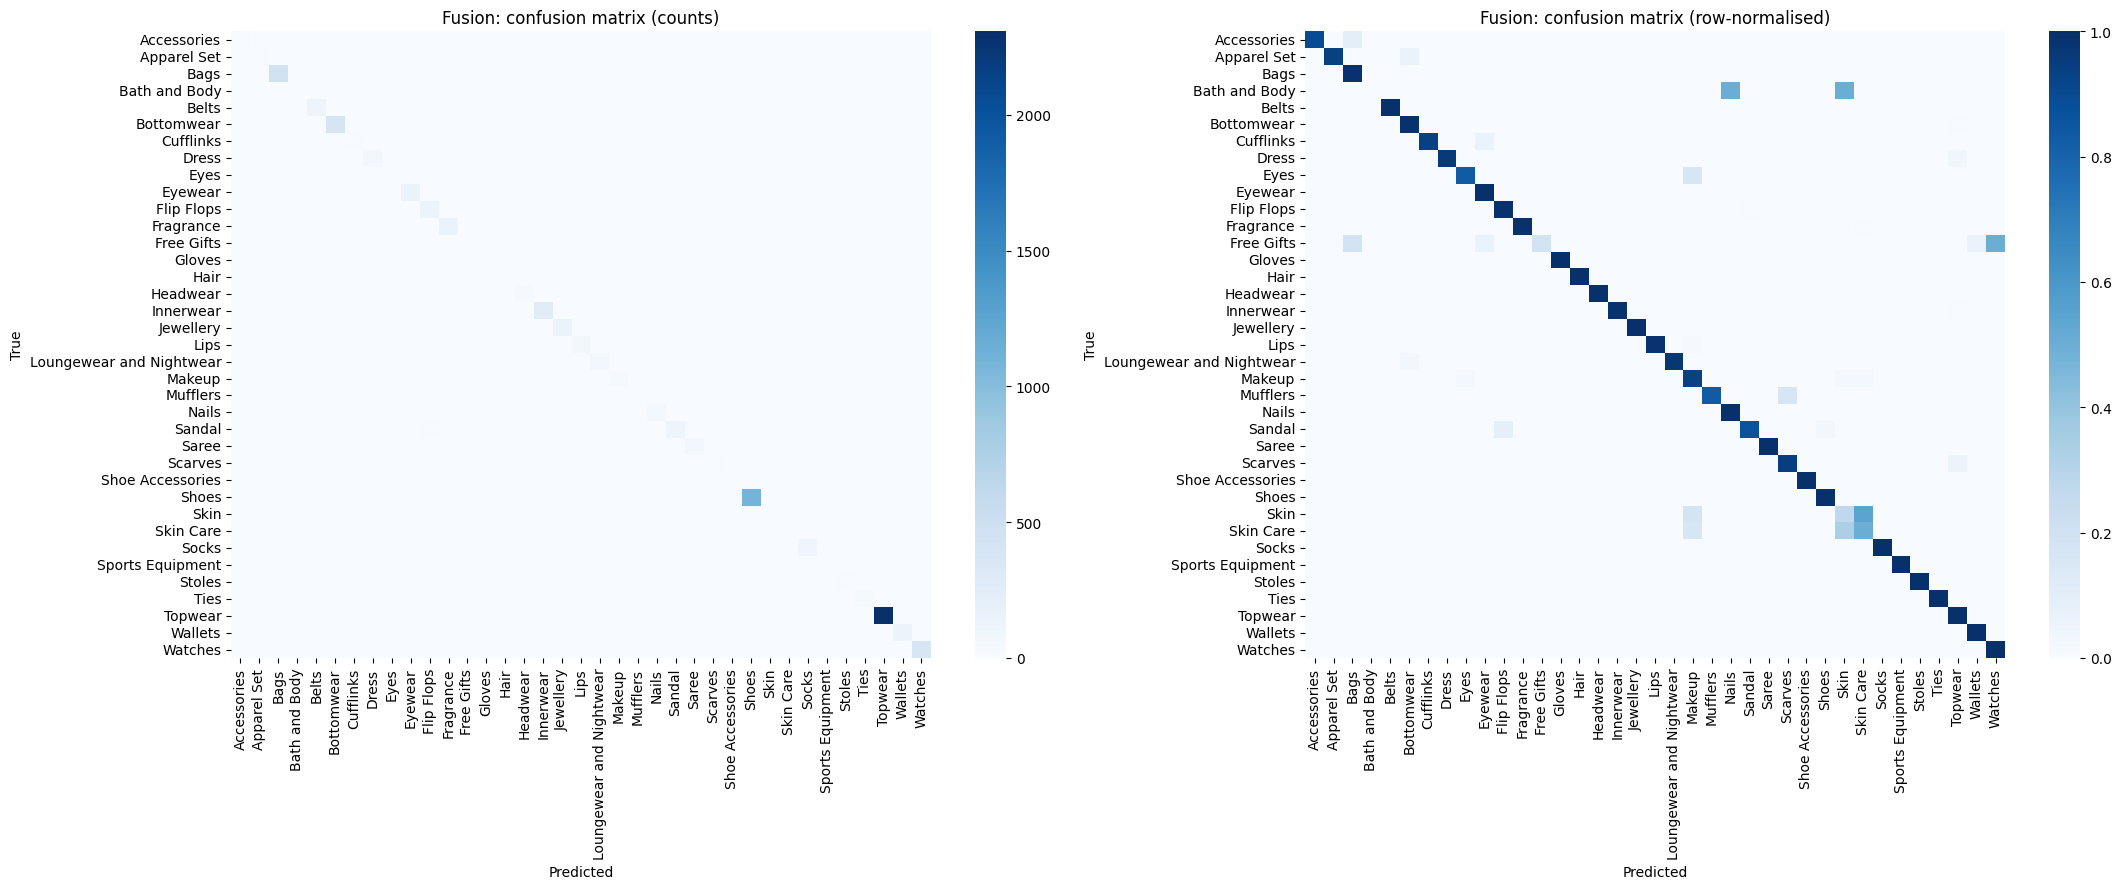

In [48]:
import seaborn as sns

cm = confusion_matrix(yt, yp, labels=labels_all)
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, ax = plt.subplots(1, 2, figsize=(22, 9))
sns.heatmap(cm, cmap="Blues", ax=ax[0], xticklabels=class_names, yticklabels=class_names)
ax[0].set_title("Fusion: confusion matrix (counts)")
sns.heatmap(cm_norm, cmap="Blues", ax=ax[1], xticklabels=class_names, yticklabels=class_names, vmin=0, vmax=1)
ax[1].set_title("Fusion: confusion matrix (row-normalised)")
for a in ax:
    a.set_xlabel("Predicted"); a.set_ylabel("True")
plt.tight_layout(); plt.show()

- The counts matrix is dominated by large classes (Topwear 2,309 and Shoes 1,102 test rows); all of them lie almost perfectly on the diagonal. This view hides rare classes, which is why the row-normalised view is also given.
- The row-normalised matrix is a clean diagonal for almost all of the 37 classes.
- The off-diagonal cells are concentrated in a few related groups: personal-care classes (Skin, Skin Care, Makeup, Bath and Body, Eyes, Nails), Free Gifts (mostly predicted as Watches) and a few similar pairs (Sandal vs Flip Flops, Dress vs Topwear).
- Errors therefore come from semantically close or ambiguously labelled classes, not from random confusion.

---
- Say matrisində böyük siniflər (Topwear 2,309, Shoes 1,102) üstünlük təşkil edir və demək olar ki, tam diaqonaldadır. Bu görünüş nadir sinifləri gizlədir, ona görə normallaşdırılmış variant da verilib.
- Normallaşdırılmış matris 37 sinifin böyük əksəriyyəti üçün təmiz diaqonaldır.
- Diaqonaldan kənar xanalar bir neçə əlaqəli qrupda cəmlənir: şəxsi baxım siniflər (Skin, Skin Care, Makeup, Bath and Body, Eyes, Nails), Free Gifts (əsasən Watches kimi proqnozlaşdırılır) və bəzi oxşar cütlər (Sandal–Flip Flops, Dress–Topwear).
- Deməli səhvlər təsadüfi deyil, mənaca yaxın və ya qeyri-müəyyən etiketli siniflərdən gəlir.

,A,B,C,support,C_minus_B
Bath and Body,0.000,0.000,0.000,2,0.000
Skin,0.154,0.720,0.300,11,-0.420
Free Gifts,0.111,0.316,0.316,16,0.000
Skin Care,0.667,0.632,0.462,12,-0.170
Eyes,0.222,0.769,0.833,6,0.064
Makeup,0.791,0.936,0.905,46,-0.031
Mufflers,0.667,0.909,0.909,6,0.000
Sandal,0.844,0.916,0.916,145,0.000
Flip Flops,0.871,0.944,0.944,137,0.000
Accessories,0.857,0.944,0.944,19,0.000


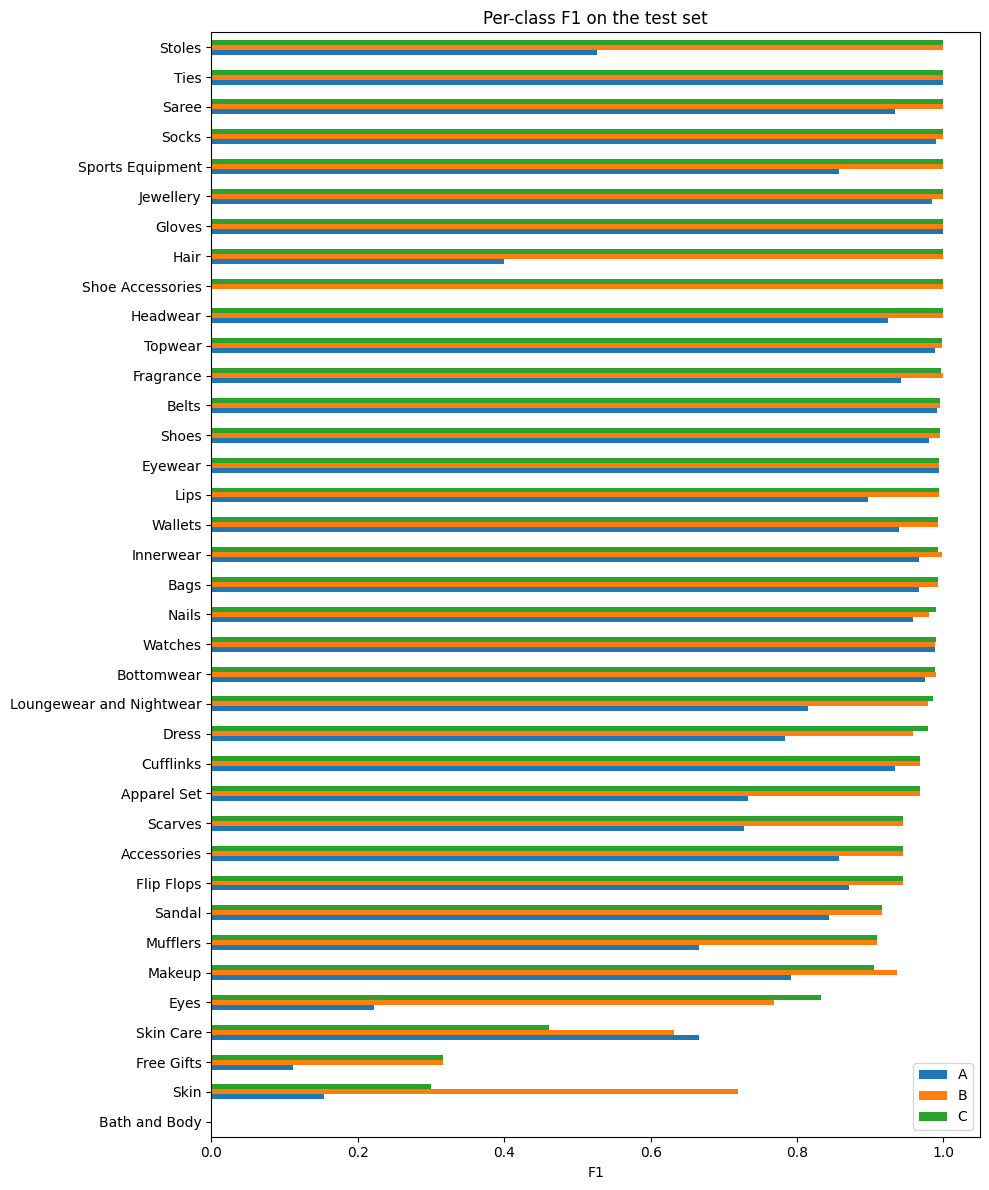

In [49]:
# Per-class F1
rows = {}
for key, nm in [("A_image", "A"), ("B_text", "B"), ("C_fusion", "C")]:
    t = predictions[key]["y_true"]; p = predictions[key]["y_pred"]
    rows[nm] = f1_score(t, p, labels=labels_all, average=None, zero_division=0)

f1_df = pd.DataFrame(rows, index=class_names)
f1_df["support"] = np.bincount(yt, minlength=len(class_names))
f1_df["C_minus_B"] = (f1_df["C"] - f1_df["B"]).round(3)
f1_df = f1_df.sort_values("C")
display(f1_df.round(3))

f1_df[["A", "B", "C"]].plot(kind="barh", figsize=(10, 12))
plt.title("Per-class F1 on the test set"); plt.xlabel("F1"); plt.tight_layout(); plt.show()

The overall macro F1 hides which classes are handled well or badly. This table and chart compare A (image), B (text) and C (fusion) class by class, with the test support (number of test rows) for each class, so we can say on which classes fusion helped.

- Most classes have F1 above 0.95 for both text and fusion, including all large classes (Topwear 0.998, Shoes 0.995, Bags 0.992, Bottomwear 0.989).
- The image-only model is clearly weaker on small or visually similar classes (e.g. Stoles 0.526, Dress 0.784, Skin 0.154), where text is decisive.
- Worst classes for fusion: **Bath and Body** (F1 0.000, n = 2), **Skin** (0.300, n = 11) and **Skin Care** (0.462, n = 12). Next are Free Gifts (0.316, n = 16) and Shoe Accessories-type rare classes. All of them have very few test rows, so their F1 is unstable (one or two examples change it a lot).
- Fusion vs text per class: fusion is equal on most classes, better on a few (Eyes +0.064, Dress +0.020, Nails +0.010, Loungewear +0.007) and worse on others (Skin −0.420, Skin Care −0.170, Makeup −0.031, Innerwear −0.006).
- The whole macro F1 gap between fusion and text comes mainly from the personal-care classes Skin and Skin Care.

---
Ümumi macro F1 hansı siniflərin yaxşı, hansıların pis olduğunu gizlədir. Bu cədvəl və qrafik A (şəkil), B (mətn) və C (fusion) modellərini sinif-sinif müqayisə edir və hər sinif üçün test support-unu (test sətri sayını) göstərir, beləliklə fusion-un hansı siniflərdə kömək etdiyini deyə bilirik.

- Mətn və fusion üçün siniflərin çoxunda F1 0.95-dən yüksəkdir, bütün böyük siniflər daxil (Topwear 0.998, Shoes 0.995, Bags 0.992, Bottomwear 0.989).
- Yalnız şəkil modeli kiçik və ya vizual oxşar siniflərdə xeyli zəifdir (məs. Stoles 0.526, Dress 0.784, Skin 0.154), orada mətn həlledicidir.
- Fusion üçün ən pis siniflər: **Bath and Body** (F1 0.000, n = 2), **Skin** (0.300, n = 11) və **Skin Care** (0.462, n = 12). Sonra Free Gifts (0.316, n = 16) gəlir. Hamısının test sətri çox azdır, ona görə F1 qeyri-sabitdir (1-2 nümunə onu çox dəyişir).
- Sinif üzrə fusion və mətn - fusion siniflərin çoxunda bərabərdir, bir neçəsində yaxşıdır (Eyes +0.064, Dress +0.020, Nails +0.010, Loungewear +0.007), bir neçəsində pisdir (Skin −0.420, Skin Care −0.170, Makeup −0.031, Innerwear −0.006).
- Fusion ilə mətn arasındakı macro F1 fərqi əsasən şəxsi baxım siniflərindən (Skin və Skin Care) gəlir.

## Error Analysis: Misclassified Examples

In [50]:
test_idx = test_df.reset_index(drop=True)
err = test_idx.copy()
err["true"] = [class_names[i] for i in yt]
err["pred"] = [class_names[i] for i in yp]
err["pred_B"] = [class_names[i] for i in predictions["B_text"]["y_pred"]]
err["pred_A"] = [class_names[i] for i in predictions["A_image"]["y_pred"]]
wrong = err[err["true"] != err["pred"]]

print("Fusion errors:", len(wrong), "of", len(err))
display(wrong[["id", "text", "true", "pred", "pred_A", "pred_B"]].head(20))

Fusion errors: 81 of 6657


,id,text,true,pred,pred_A,pred_B
74,57892,Biotique Women Bio Almond Eye Cream Beige Casual,Skin Care,Makeup,Skin,Skin
169,13580,Hanes Men Pack of 2 Half Contrast Piping Ringe...,Innerwear,Topwear,Innerwear,Innerwear
177,57543,Lotus Herbals Floralglam Nude Glow 019 Nude,Lips,Makeup,Lips,Makeup
186,2712,Disney Kids Girl's Halter Neck Blue Kidswear B...,Dress,Topwear,Dress,Topwear
265,15388,Fila Men Glide Black Slippers Black Casual,Sandal,Flip Flops,Flip Flops,Flip Flops
382,44965,Maxima Men White Dial Watch White Casual,Free Gifts,Watches,Free Gifts,Watches
467,13925,Nike Men Solarsoft Slide Red Slippers Red Casual,Sandal,Flip Flops,Sandal,Flip Flops
541,25402,Nike Men Striped Manchester United Red Scarf R...,Mufflers,Scarves,Mufflers,Scarves
578,59860,Olay White Radiance Advanced Whitening Brighte...,Skin,Makeup,Jewellery,Skin
806,53566,Q&Q Kids Unisex White Dial Watch White Casual,Free Gifts,Watches,Watches,Watches


In [51]:
wrong_both = wrong[(wrong["pred_A"] != wrong["true"]) & (wrong["pred_B"] != wrong["true"])]
only_text_right = wrong[(wrong["pred_B"] == wrong["true"])]
only_img_right  = wrong[(wrong["pred_A"] == wrong["true"])]
print(len(wrong_both), len(only_text_right), len(only_img_right))

sel = pd.concat([wrong_both.sample(min(4, len(wrong_both)), random_state=1),
    only_text_right.sample(min(2, len(only_text_right)), random_state=1),
    only_img_right.sample(min(2, len(only_img_right)), random_state=1),]).drop_duplicates("id")

41 19 29


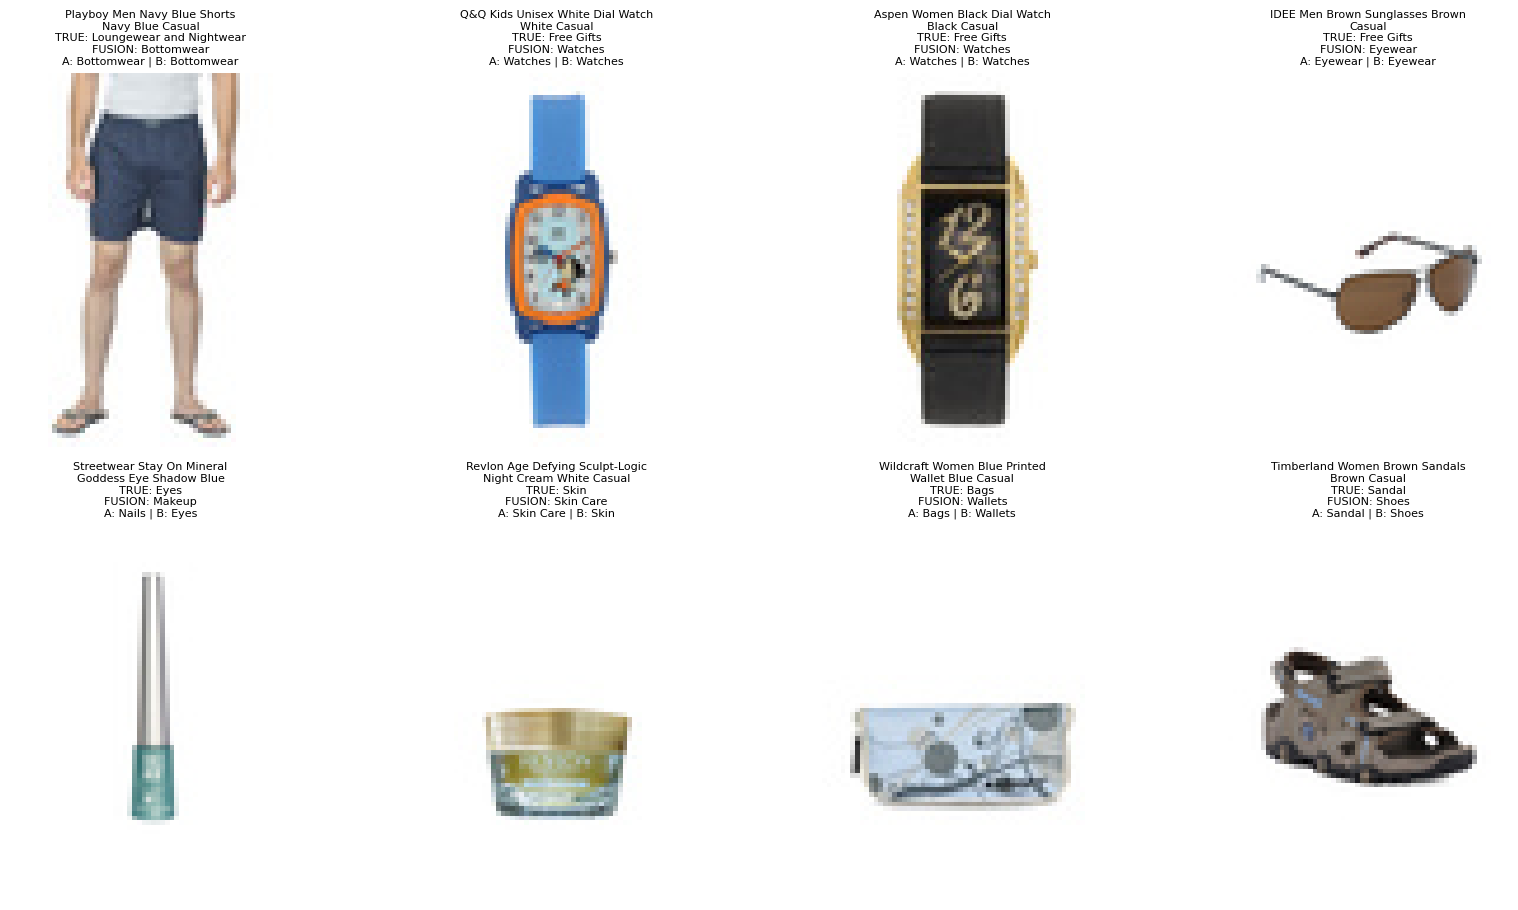

In [52]:
from PIL import Image
import textwrap

n = len(sel)
cols = 4
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 4.6 * rows))
axes = np.array(axes).reshape(-1)

for ax, (_, r) in zip(axes, sel.iterrows()):
    ax.imshow(Image.open(r["img_path"]).convert("RGB"))
    ax.axis("off")
    title = textwrap.fill(r["text"], 32) + f"\nTRUE: {r['true']}\nFUSION: {r['pred']}\nA: {r['pred_A']} | B: {r['pred_B']}"
    ax.set_title(title, fontsize=8)
for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout(); plt.show()

The fused model makes 81 errors out of 6,657 test rows. Of these, 41 were also wrong in both single-modality models, 19 were right in the text-only model (image misled fusion) and 29 were right in the image-only model.

Most errors are caused by questionable or overlapping labels (Free Gifts, Skin/Skin Care, Sandal/Flip Flops), not by model weakness. In 19 cases the image misled the fused model while text alone was right.

---
Fusion 6,657 test sətrindən 81-də səhv edir. Bunların 41-i hər iki tək-modallıq modelində də səhv idi, 19-da mətn modeli düz tapmışdı (şəkil fusion-u çaşdırıb), 29-da şəkil modeli düz tapmışdı.
 
Səhvlərin çoxu model zəifliyindən yox, şübhəli və ya üst-üstə düşən etiketlərdən (Free Gifts, Skin/Skin Care, Sandal/Flip Flops) gəlir. 19 halda mətn tək düz tapdığı halda şəkil fusion-u çaşdırıb.

## Verdict: Did Fusion Help?

In [53]:
from sklearn.metrics import f1_score
rng = np.random.default_rng(0)
yB = np.array(predictions["B_text"]["y_pred"])
n = len(yt)
diffs = []
for _ in range(200):
    idx = rng.integers(0, n, n)
    fC = f1_score(yt[idx], yp[idx], average="macro")
    fB = f1_score(yt[idx], yB[idx], average="macro")
    diffs.append(fC - fB)
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"macro F1 (fusion - text): mean {np.mean(diffs):.4f}, 95% CI [{lo:.4f}, {hi:.4f}]")

macro F1 (fusion - text): mean -0.0131, 95% CI [-0.0282, 0.0097]


In this project, the text model achieved the best performance with an F1-score of 0.914. This is because product names (e.g., 'Puma Men Grey T-shirt') convey the category directly and completely to the model. The Fusion model (0.900 F1), which combines both images and text, lagged slightly behind the text baseline.

This raises the question: is this difference significant? Statistical evaluations (bootstrapping) indicate that there is no statistically significant difference between the Fusion and text models. The minor dip in the Fusion model's performance is merely due to random variance.

The reason the Fusion model failed to outperform the text baseline stems from visually similar images misleading the model, label noise (mislabeled items) within the dataset, and a few errors in small categories with limited samples heavily skewing the overall score downward.

In this dataset, text is the dominant modality. A zero or slightly negative fusion improvement is not a failure, but rather an expected and honest scientific finding.

---
Bu layihədə mətn modeli (0.914 F1) ən yaxşı nəticəni verdi. Çünki məhsulların adları (məsələn, "Puma Men Grey T-shirt") kateqoriyanı modelə birbaşa və tam başa salır. Şəkilləri və mətni birləşdirən Fusion modeli (0.900 F1) isə mətn modelindən çox cüzi geri qaldı.

Bu zaman aual yaranır, fərq realdırmı? Statistik yoxlamalar (bootstrap) göstərir ki, Fusion və Mətn modelləri arasında real bir fərq yoxdur. Fusion modelinin bir az aşağı nəticə göstərməsi sadəcə təsadüfi dəyişkənlikdən qaynaqlanır.

Fusion modelinin irəli düşə bilməməsinə səbəb, bir-birinə bənzəyən şəkillərin modeli çaşdırması, datasetdəki bəzi etiketlərin səhv (qarışıq) vurulması və çox az məlumatı olan kiçik kateqoriyalarda baş verən bir neçə xətanın ümumi xalı aşağı salmasıdır.

Bu datasetdə mətn dominant modallıqdır. Sıfır və ya bir qədər mənfi fusion artımı uğursuzluq yox, gözlənilən və dürüst tapıntıdır.